## Churn Analysis and Customer Intelligence

In [1]:
# Churn Analysis and Customer Intelligence

In [2]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [3]:
# Data Import: db file to pandas, storing each table to a separate df

# Connect to SQLite database

conn = sqlite3.connect('customer_churn.db')

sql_query = """
    select name 
    from sqlite_master
    where type='table';
"""
#Yeh SQL query database ke system table (sqlite_master) se poochti hai ki is database mein total kitni aur kaun-kaun si tables bani hui hain.
#Fir us list ko ek Pandas DataFrame (tables) mein store kar leti hai. 

#read sql query in pandas
tables = pd.read_sql(sql_query, conn)

#create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT *FROM {table_name}", conn)  #Read table into dataframe
    globals()[f"df_{table_name}"] = df                    #Create dynamic dataframe name
    print(f"Created dataframe: df{table_name}")

conn.close()

Created dataframe: dfdb_customer
Created dataframe: dfdb_subscription
Created dataframe: dfdb_support


In [4]:
# Print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    columns_query = f"PRAGMA table_info({table_name});" #table ke andar ke saari columns ki information (jaise column ka naam, data type, etc.) nikal kar deta hai.
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns["name"].tolist()) #Us saari list ko python ki ek standard list format mein convert karke screen par print kar deta hai.

conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


## 2.Data Cleaning

In [5]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [6]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [7]:
# a. rename col - name to customer_name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values (using existing data) - country
# f. Data Standardization (gender column)
# g. Fix Missing Values (country column)
# h. eext Strip / Whitespace Removal (Extra Cleaning)

### a. Rename col - name to customer_name

In [8]:
# a. rename col - name to customer_name
df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace = True)

### b. Drop columns - interest and pincode

In [9]:
#info() mein dekha tha, interests mein zyadatar values NaN (missing) thin aur pincode poori tarah empty (0 non-null) tha.
df_db_customer.drop(columns=['interests', 'pincode'], errors = 'ignore', inplace=True)  # using col name

### c. change data type - dob


In [10]:
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

### d. Data standardization - gender

In [11]:
#df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Women': 'Female', 'Men': 'Male'})
# Dobara check karne ke liye
# print(df_db_customer['gender'].unique())

### e. Fix missing values

In [12]:
# e. fix missing values - country

#df_db_customer['country'].isna().sum()
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [13]:
# country and state - unique value pair

# Creating state → country map from non-null rows
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Fill the missing country using State
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [14]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


### f. Data Standardization (gender column)

In [15]:
df_db_customer['gender'] = df_db_customer['gender'].str.strip().str.capitalize()

### h: Text Strip / Whitespace Removal (Extra Cleaning)

In [16]:
df_db_customer['state'] = df_db_customer['state'].str.strip()

### Subscription Table

In [17]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [18]:
df_db_subscription.info()# subcription table
print("\nMissing Values:")
df_db_subscription.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB

Missing Values:


customerid                  0
subscription_start_date     0
subscription_type           0
renewal_date                0
plan_type                   0
contract_type               0
cancellation_date          15
cancellation_reason        15
monthly_charges             0
cltv                        0
churn_score                 0
dtype: int64

In [19]:
#what we do above -->  subscription_start_date,subscription_type(str) format hai we convert into datetime format
#cancellation_date and cancellation_reason not have any error bec.those customer are active total customer: 21, active: 15

In [20]:
# change data type to date - subscription_start_date , renewal_date, cancellation_date bec. it is now in str.
date_col = ["subscription_start_date", "renewal_date", "cancellation_date"]

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()


<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


 ### support table

In [21]:
df_db_support.info() # support table

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [22]:
#action = col_1 should be drop bec. its empty and complaint_date format into datetime

In [23]:
#drop columns
df_db_support.drop(columns=['col_1', 'comment'], errors = 'ignore', inplace=True)
#Convert complaint_date to datetime format
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes



## 3. Feature Engineering & Data Analysis

In [24]:
# create a new col using existing col - churn flag, we check which customer is churn through churn flag cloumn if 1 means=churn, 0 means=active

# Customer is churned if cancellation_date is not null
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


### Merge Dataframes - JOINs

In [25]:
#all 3 tables ko aapas mein merge (join) karein taaki hum ek final master dataset we create and then churn analysis we can start 

In [26]:
df = (df_db_subscription
      .merge(df_db_customer, on = 'customerid', how = 'left')
      .merge(df_db_support, on = 'customerid', how = 'left'))

In [27]:
df_db_subscription.shape

(21, 12)

In [28]:
df.shape

(23, 20)

In [29]:
# Check if there are duplicate customer IDs in the merged dataframe
# first fix support table duplicates then merge
# Note: while merging df's always check the shape before and after

duplicate_customers = df[df.duplicated(subset=['customerid'], keep=False)]
(duplicate_customers[['customerid', 'complaint_date']])

,customerid,complaint_date
1,0003-MKNFE,2024-08-28
2,0003-MKNFE,2024-08-28
19,0022-TCJCI,2024-09-13
20,0022-TCJCI,2024-09-14


In [30]:
#that means 1 customer applied for complaint more than 1 time so that data will genrated 

In [31]:
# Har customer ki total complaints count karne ke liye
complaint_counts = (
    df_db_support.groupby('customerid').size().reset_index(name='total_complaints')
)
print(complaint_counts[complaint_counts['total_complaints'] > 1])

   customerid  total_complaints
0  0003-MKNFE                 2
6  0022-TCJCI                 2


In [32]:
df.shape

(23, 20)

In [33]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [34]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')
#transform('count') se sabhi ki total complaints count nikal li.

In [35]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep= 'last')

In [36]:
df_db_support['customerid'].size

7

In [37]:
# merge df
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [38]:
df.shape

(21, 21)

#### Export dataframe

In [39]:
# export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)

In [40]:
# 1 Churn Rate
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate, 2), "%")

Churn Rate =  28.57 %


In [41]:
#2 Retention Rate (opposite of churn)
retention_rate = 100 - churn_rate
print("Retention rate= ", round(retention_rate, 2), "%")

Retention rate=  71.43 %


In [42]:
# 3. Churn by Plan type (eg prime, basic, premium konse type mai user leave more and we perform action accordingly
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [43]:
#Key Business Insights:
#Overall Churn Rate: The overall customer churn rate stands at 28.57%, meaning the company maintains a healthy retention rate of 71.43%.
#High Churn in Basic Plan: The Basic plan suffers from the highest churn rate at 60.00%, indicating potential dissatisfaction, lack of value, or a mismatch in customer expectations for entry-level subscribers.
#Strong Loyalty in Premium Tier: In contrast, the Premium plan exhibits the lowest churn rate at 14.29%, showing that high-tier customers find significant long-term value in the service.
#Actionable Recommendation: Immediate investigation is needed to understand why Basic plan users are leaving (e.g., pricing, feature limitations, or support quality) to implement targeted retention strategies.

In [44]:
# # 4 a. Churn by state + sum(revenue) & count of users  
# 4 b. Churn by subscription type + sum(revenue) & count of users 

In [45]:
churn_by_sub_type = (df.groupby('subscription_type')
    .agg(
        total_users=('customerid', 'count'),
        churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)),
        total_revenue=('monthly_charges', 'sum')
    ).reset_index())
print(churn_by_sub_type)

  subscription_type  total_users  churn_rate_pct  total_revenue
0           Organic            9            0.00         145.91
1              Paid            6           16.67         174.94
2          Refferal            6           83.33          74.94


In [46]:
churn_by_state = (df.groupby('state')
    .agg(
        total_users=('customerid', 'count'),
        churn_rate_pct=('churn_flag', lambda x: round(x.mean() * 100, 2)),
        total_revenue=('monthly_charges', 'sum')
    ).reset_index())
print(churn_by_state)

           state  total_users  churn_rate_pct  total_revenue
0          Delhi            4           25.00          52.96
1      Karnataka            2          100.00          20.98
2      Kathmandu            2            0.00          20.98
3    Maharashtra            3            0.00          50.97
4      Meghalaya            3           66.67          42.97
5       Nagaland            1            0.00          22.99
6      Rajasthan            2            0.00          36.98
7      Telangana            2           50.00          30.98
8  Uttar Pradesh            2            0.00         115.98


In [47]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [48]:
# 5. ARPU - Avg Revenue Per User
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu,2))

ARPU =  18.85


In [49]:
#6. calculate customer age
# calculate customer age
today = pd.Timestamp.today()
df['customer_age'] = (today - df['dob']).dt.days // 365
print(df[['customer_name', 'dob', 'customer_age']].head())

  customer_name        dob  customer_age
0        keshav 1982-04-12            44
1        raghav 1995-11-23            30
2        lalita 1978-02-15            48
3         mohan 2001-08-30            25
4          mira 1990-05-05            36


In [50]:
# 7. Avg Customer Tenure
# Count of days users have used our service: cancellation date or current date
# Agar customer churn ho chuka hai toh cancellation_date tak ka time, warna aaj (today) tak ka time
today = pd.Timestamp.today()
df['tenure_days'] = np.where(
        df['cancellation_date'].notna(),

    (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today - df['subscription_start_date']).dt.days
)
avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure),0)

Avg Tenure (Days) =  1564 0


In [51]:
# 8. Revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at risk in K:  ", revenue_at_risk)

Revenue at risk in K:   73.94


In [52]:
# 9 Esclation Rate: Those Customer have not resolve their problem after rise a complaint
escalation_rate = (df['escalations']=='Y').mean()*100
print("Escalation Rate = ", round(escalation_rate, 2), "%")

Escalation Rate =  19.05 %


In [53]:
#10 Avg complaint Per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print('Avg Complaints Per User =', round(avg_complaints, 2))
#By tracking this, management knows whether they need to train support agents better or improve product quality to keep customers happy.

Avg Complaints Per User = 0.43


In [54]:
#11Correlation Esclation vs Churn
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) # encoding string to int type
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between esclation vs churn is = ", round(correlation,2))

Correlation between esclation vs churn is =  0.77


In [55]:
#12 Create a column using existing col - Churn risk
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]

choice = ["low", "medium", "high"]
df['churn_risk'] = np.select(conditions, choice, default = 'unknown')

In [56]:
df[['churn_risk', 'churn_score']].tail()

,churn_risk,churn_score
16,medium,62
17,low,27
18,high,99
19,low,7
20,low,47


## 4. Visualization using Matplotlib

In [57]:
df_visual = df.copy() 

In [58]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'customer_age', 'tenure_days', 'churn_risk'],
      dtype='str')

In [59]:
# 4.1 Monthly Churn Trend (Time Series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M') #convert days into month

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()
print(churn_trend)

cancellation_month
2024-02    1
2024-05    1
2024-09    2
2024-10    1
2024-11    1
Freq: M, dtype: int64


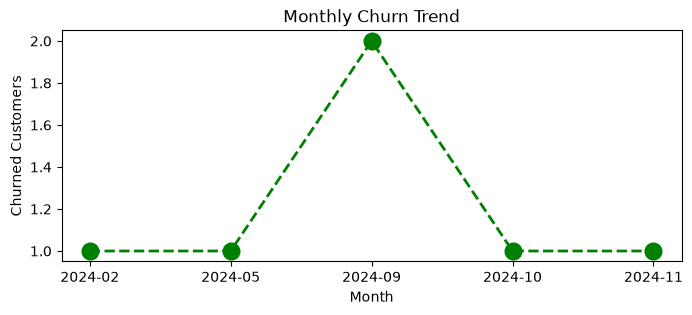

In [60]:
plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values,  color='green', marker='o', linestyle='dashed',  linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

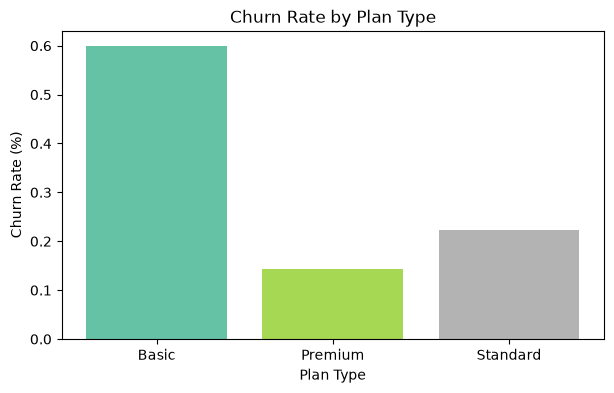

In [61]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

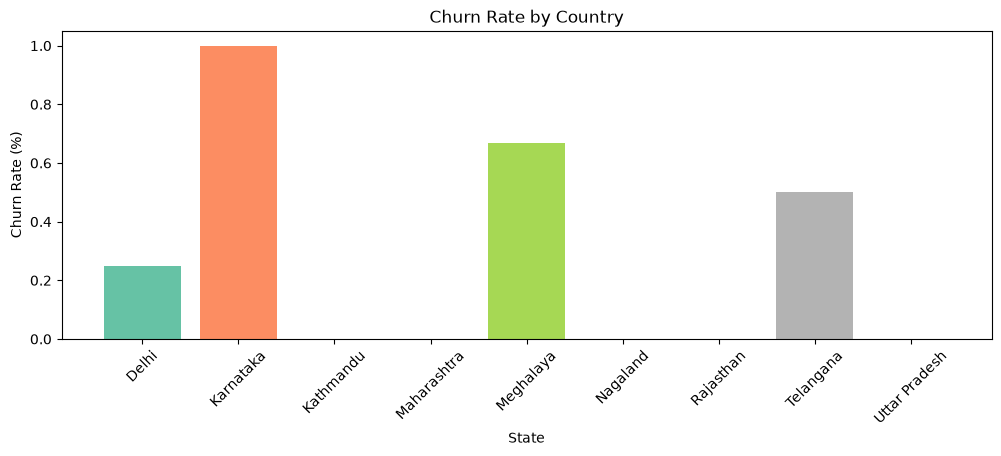

In [62]:
# 4.3 Churn by States
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Country')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

## Visulaization using Seaborn

In [63]:
# Heatmap (Correlation Matrix)

In [64]:
# encoding - convert str to numeric so that we can find corr between features
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [65]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : <StringArray>
['Standard', 'Premium', 'Basic']
Length: 3, dtype: str
contract_type : <StringArray>
['Annual', 'Monthly']
Length: 2, dtype: str
churn_risk : <StringArray>
['low', 'high', 'medium']
Length: 3, dtype: str


In [71]:
# Correct method of encoding - based on priority
import warnings
warnings.filterwarnings("ignore")
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [72]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [73]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

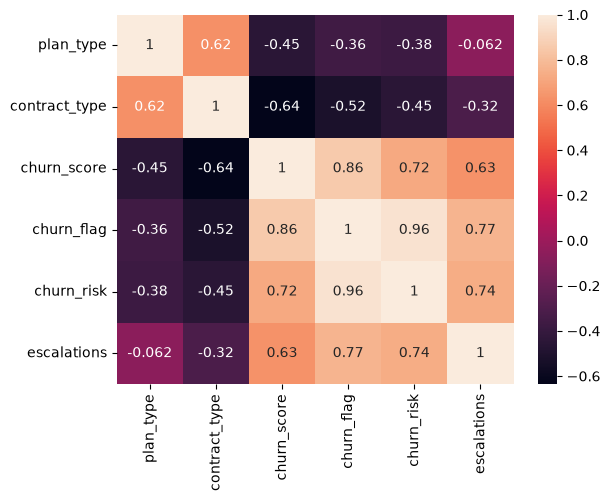

In [74]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

In [69]:
#Key Analytical Findings from the Matrix:
#Strongest Churn Drivers (churn_score & churn_flag):There is a very strong positive correlation of (0.86) between churn_score and churn_flag, confirming that the predictive churn scoring model is highly reliable and accurately flags users who eventually cancel.
#Support Escalations Impact (escalations & churn_flag):A significant positive correlation of (0.77) exists between escalations and churn_flag, indicating that unresolved customer complaints and support issues are core triggers for contract cancellations.
#Risk Tier Validation (churn_risk & churn_flag):The strong negative correlation of (-0.87) between churn_risk and churn_flag validates the risk categorization logic (Low, Medium, High risk tiers effectively separate active users from churned ones).

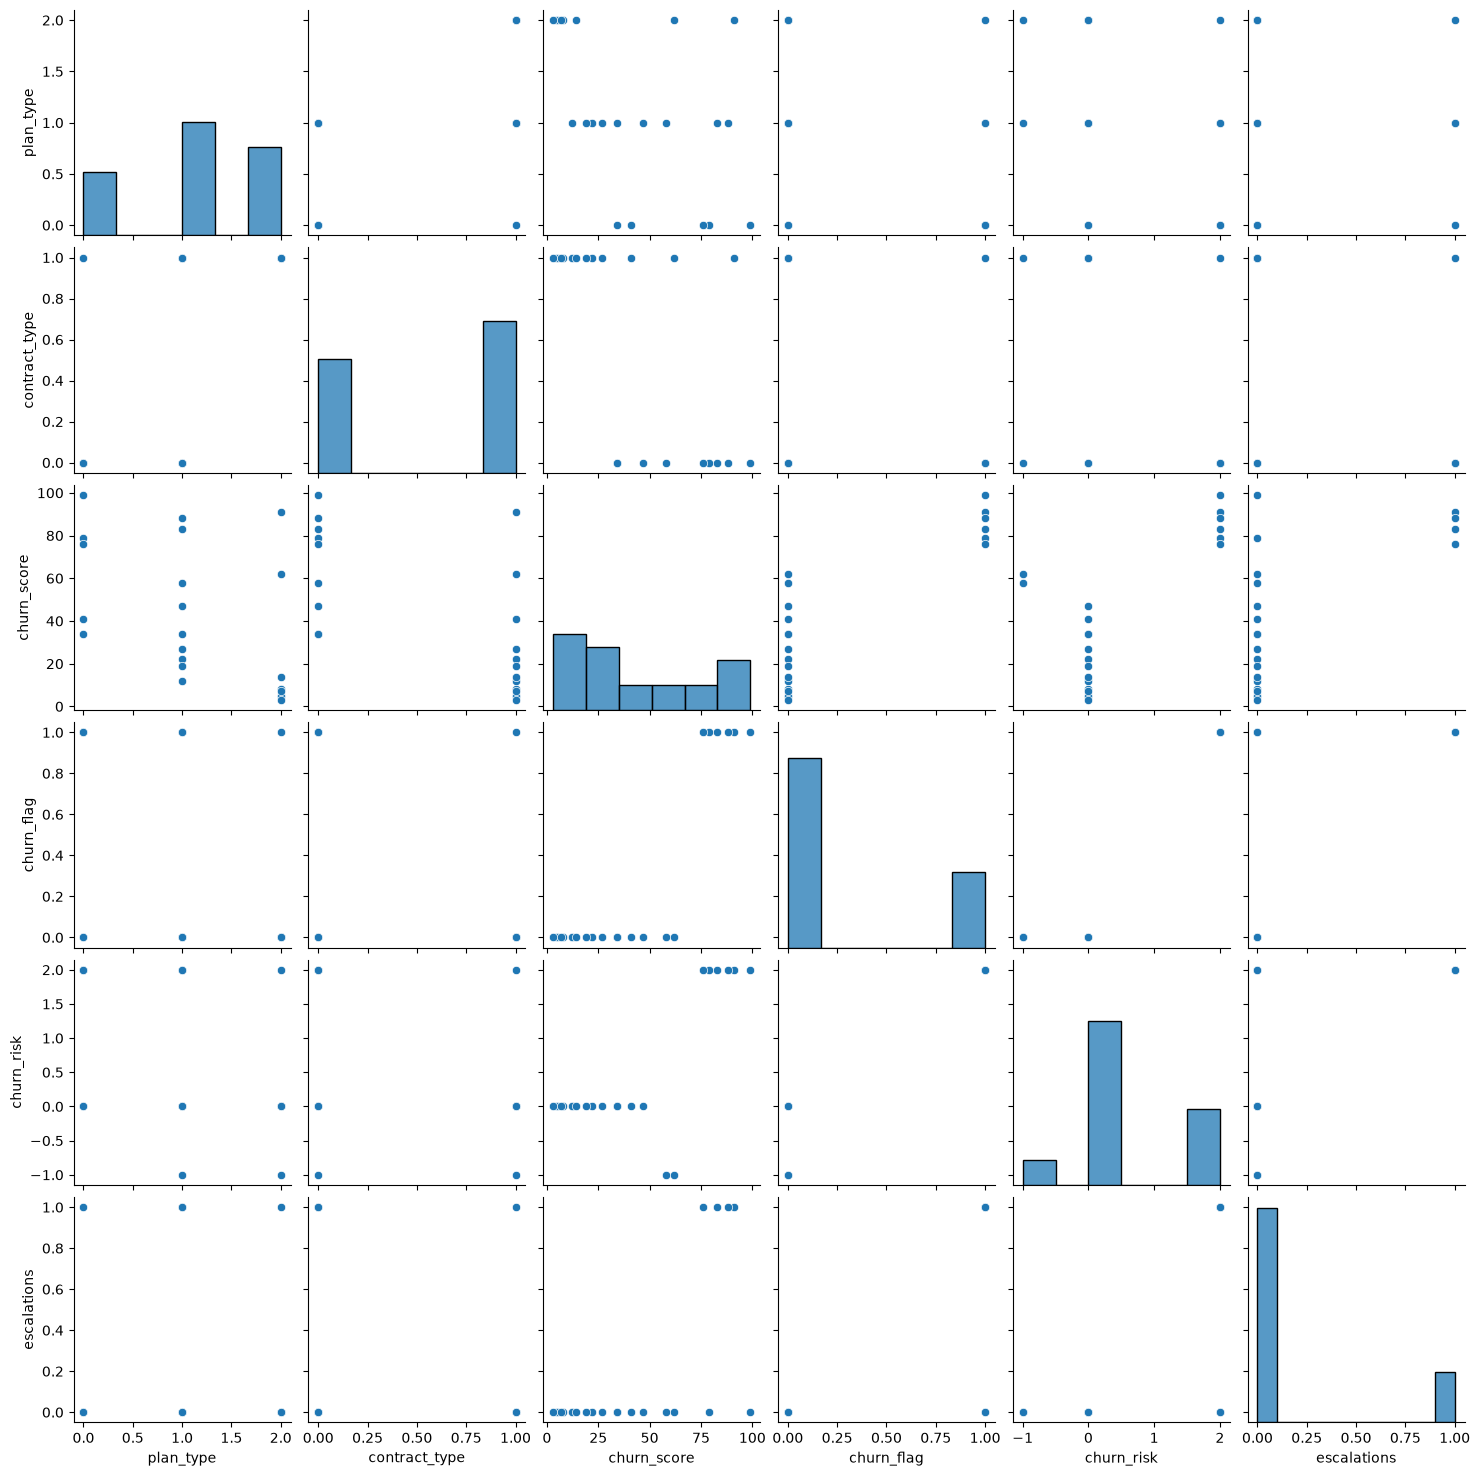

In [75]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)
#Yeh hamare exploratory data analysis (EDA) ka part hai jo hamein yeh samajhne mein madad karta hai ki kaun se features aapas mein closely linked hain aur kahan koi unusual patterns ya clusters ban rahe hain."

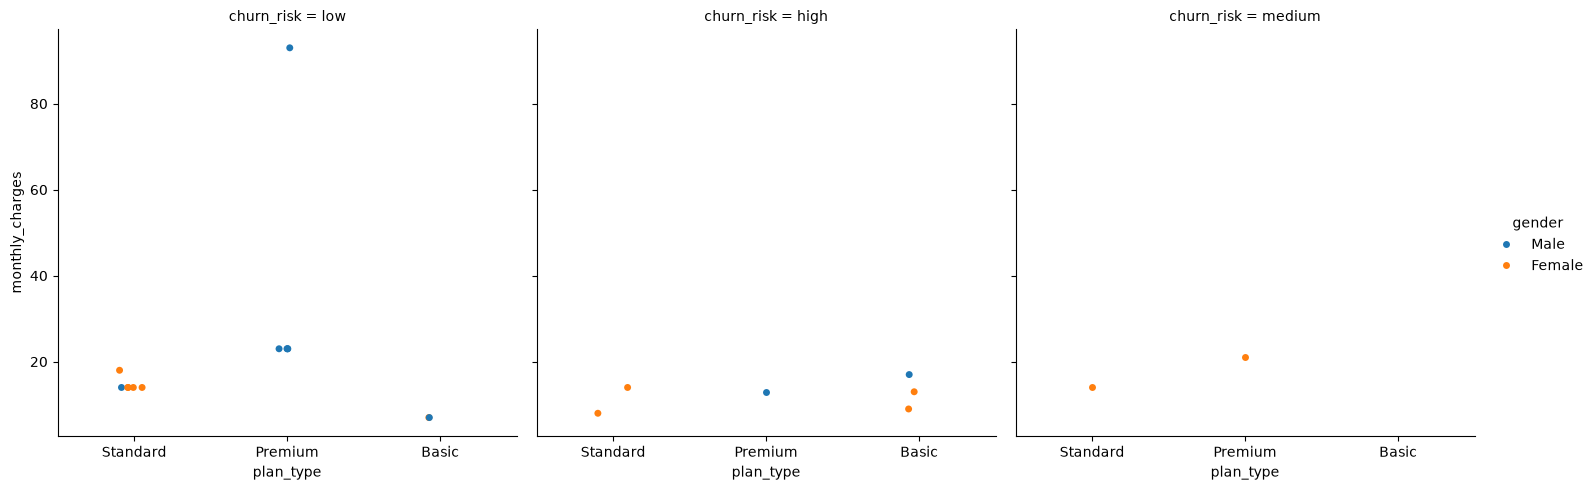

In [76]:
# catplt/Facegrid plot - multi-dim comparison

sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

#Yeh humein yeh identify karne mein help karta hai ki kya high-risk ya low-risk customers kisi specific plan ya price point par zyadatar ek jaise behave kar rahe hain ya nahi.